In [11]:
from datasets import load_dataset
import pandas as pd
train = load_dataset("Multimodal-Fatima/CUB_train", split="train")
test = load_dataset("Multimodal-Fatima/CUB_test", split="test")


In [12]:
#Split data to get validation
split = train.train_test_split(
    test_size=0.20,
    stratify_by_column="label",
    seed=42,
)

train = split["train"]
validation = split["test"]

print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

Training: 4795
Validation: 1199
Test: 5794


In [13]:
import pandas as pd

# Only convert the labels; no need to load images.
labels_df = train.select_columns(["label"]).to_pandas()

class_counts = (
    labels_df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="image_count")
)

# Add readable species names.
class_counts["species"] = class_counts["label"].apply(
    train.features["label"].int2str
)

print("Number of classes:", len(class_counts))
print("Total training images:", class_counts["image_count"].sum())

display(class_counts[["label", "species", "image_count"]])

Number of classes: 200
Total training images: 4795


,label,species,image_count
0,0,Black footed Albatross,24
1,1,Laysan Albatross,24
2,2,Sooty Albatross,24
3,3,Groove billed Ani,24
4,4,Crested Auklet,24
...,...,...,...
195,195,House Wren,23
196,196,Marsh Wren,24
197,197,Rock Wren,24
198,198,Winter Wren,24


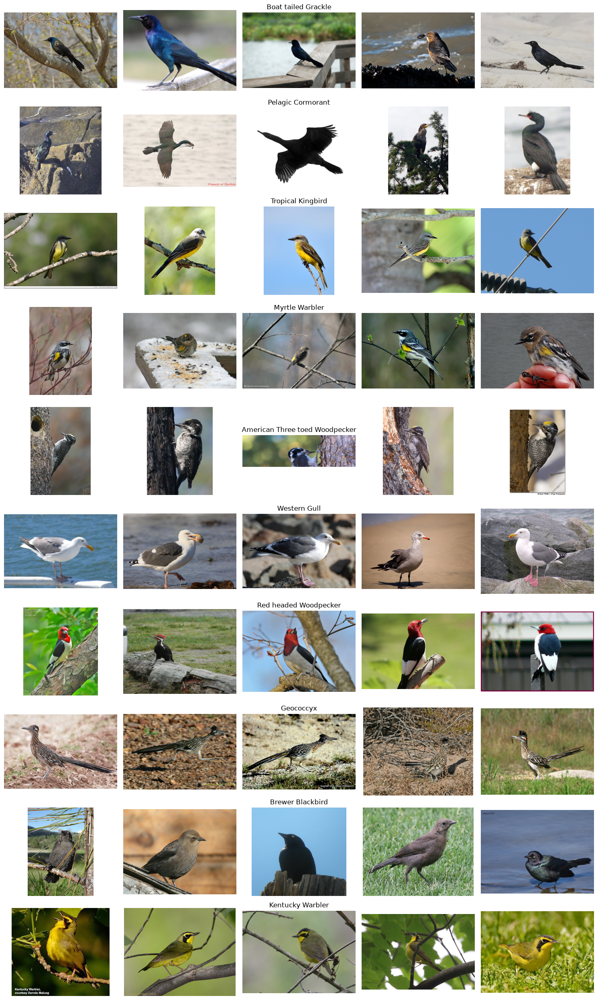

In [47]:
import random
from collections import defaultdict
import matplotlib.pyplot as plt

rng = random.Random(78)  # Change the seed for a different selection.

# Group training-row indices by class without opening the images.
indices_by_class = defaultdict(list)

for index, label in enumerate(train["label"]):
    indices_by_class[label].append(index)

# Only consider classes with at least 5 training images.
eligible_classes = [
    label for label, indices in indices_by_class.items()
    if len(indices) >= 5
]

if len(eligible_classes) < 10:
    raise ValueError("Need at least 10 classes with 5 images each.")

selected_classes = rng.sample(sorted(eligible_classes), 10)

fig, axes = plt.subplots(10, 5, figsize=(15, 25))

for row, label in enumerate(selected_classes):
    species = train.features["label"].int2str(label)
    selected_indices = rng.sample(indices_by_class[label], 5)

    for col, index in enumerate(selected_indices):
        image = train[index]["image"].convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        # Show the species name above the middle image of each row.
        if col == 2:
            axes[row, col].set_title(species, fontsize=12)

plt.tight_layout()
plt.show()

In [49]:
from PIL import Image, ImageOps

def resize_and_pad(image, size=224):
    return ImageOps.pad(
        image.convert("RGB"),
        size=(size, size),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0),  # Gray padding
        centering=(0.5, 0.5),   # Center the image
    )


In [50]:
train_resized = train.map(
    lambda sample: {
        "image": resize_and_pad(sample["image"], size=320)
    },
    writer_batch_size=16,
    desc="Resizing training images",
)

Resizing training images: 100%|██████████| 4795/4795 [00:44<00:00, 107.22 examples/s]


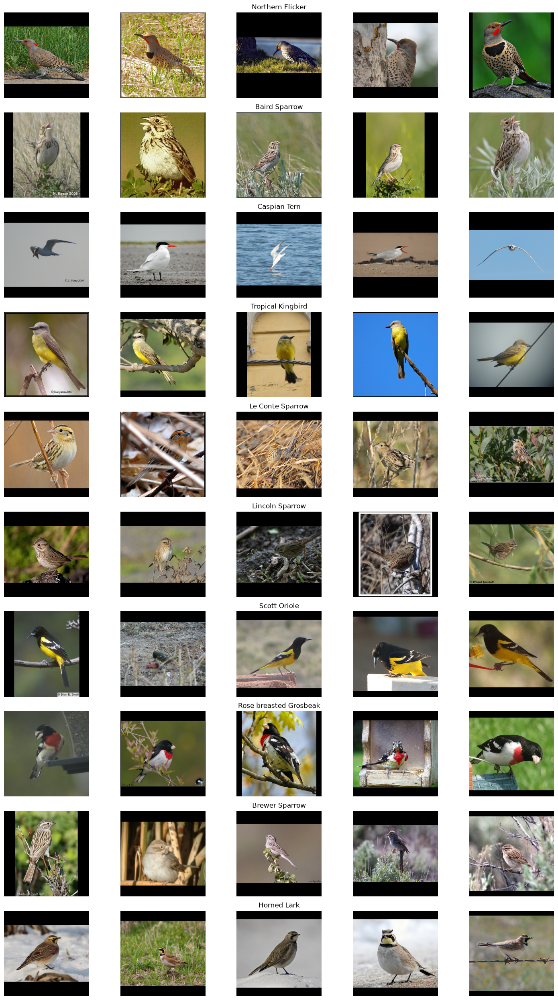

In [51]:
import random
from collections import defaultdict
import matplotlib.pyplot as plt

rng = random.Random(54)  # Change the seed for a different selection.

# Group training-row indices by class without opening the images.
indices_by_class = defaultdict(list)

for index, label in enumerate(train_resized["label"]):
    indices_by_class[label].append(index)

# Only consider classes with at least 5 training images.
eligible_classes = [
    label for label, indices in indices_by_class.items()
    if len(indices) >= 5
]

if len(eligible_classes) < 10:
    raise ValueError("Need at least 10 classes with 5 images each.")

selected_classes = rng.sample(sorted(eligible_classes), 10)

fig, axes = plt.subplots(10, 5, figsize=(15, 25))

for row, label in enumerate(selected_classes):
    species = train_resized.features["label"].int2str(label)
    selected_indices = rng.sample(indices_by_class[label], 5)

    for col, index in enumerate(selected_indices):
        image = train_resized[index]["image"].convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        # Show the species name above the middle image of each row.
        if col == 2:
            axes[row, col].set_title(species, fontsize=12)

plt.tight_layout()
plt.show()